# ClinVar Missense Variant Dataset Preparation

This notebook prepares the shared dataset for our Group 8 project, where we predict whether a missense variant is pathogenic or benign. A missense variant is a DNA change that replaces one amino acid in a protein with another.

The generated datasets and feature configuration are saved in the `data/processed/` folder.

The notebook downloads the ClinVar data, keeps the variants we need, adds conservation, population frequency and amino acid features, checks the result and saves the files below. Missing values, scaling and model training are left to each team member.

## Output files

1. **clinvar_expanded_model_features.csv**: the file for training. It has the variant ID, gene name, 28 features and the label (1 for pathogenic, 0 for benign).
2. **clinvar_expanded_project_dataset.csv**: the same variants with extra details such as genome position and scores from tools like CADD and REVEL. Use it for comparison only, not as model input.
3. **clinvar_full_annotated_all_rows.csv**: every original row, with the reason each removed row was dropped.
4. **feature_config.json**: the column lists for feature sets A, B and D.

Some population frequency values are missing. They are left empty so each person can fill them in their own way.

## 1. Setup

Install Biopython for the BLOSUM62 table and create the working folder.

In [ ]:
# Install Biopython in the environment before running this notebook.

In [2]:
from pathlib import Path
import hashlib
import json
import platform
import subprocess
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio.Align import substitution_matrices

pd.set_option("display.max_columns", 160)
pd.set_option("display.width", 180)

# Find the repository root when run from the root or notebooks/ folder.
SEARCH_DIRS = (Path.cwd(), *Path.cwd().parents)
BASE_DIR = next((p for p in SEARCH_DIRS if (p / "data" / "processed").is_dir()), Path.cwd())
WORKDIR = BASE_DIR / "data" / "processed"
RAW_DIR = BASE_DIR / "data" / "raw"
WORKDIR.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)

DATA_URL = (
    "https://zenodo.org/records/15275244/files/"
    "cleaned_ClinVar_with_preds.csv?download=1"
)
DATA_FILE = RAW_DIR / "cleaned_ClinVar_with_preds.csv"
EXPECTED_MD5 = "64d4ea4deea22e6835b6ec713fb7645b"

print("Working directory:", WORKDIR)
print("Platform:", platform.platform())
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Python: 3.13.18
pandas: 2.2.3
numpy: 2.1.3


## 2. Download the data

Download the cleaned ClinVar file and check that it matches the expected checksum, so everyone uses the same file.

In [3]:
def download_file(url, destination):
    destination = Path(destination)
    if destination.exists() and destination.stat().st_size > 1_000_000:
        print("Using existing file:", destination)
        return
    print("Downloading:", url)
    urllib.request.urlretrieve(url, destination)
    print(f"Saved {destination} ({destination.stat().st_size / 1024**2:.1f} MB)")


def md5sum(path, chunk_size=1024 * 1024):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


download_file(DATA_URL, DATA_FILE)

actual_md5 = md5sum(DATA_FILE)
print("Expected MD5:", EXPECTED_MD5)
print("Actual MD5:  ", actual_md5)

if actual_md5 != EXPECTED_MD5:
    raise ValueError("Checksum mismatch. Delete the file and download it again.")

Downloading: https://zenodo.org/records/15275244/files/cleaned_ClinVar_with_preds.csv?download=1
Expected MD5: 64d4ea4deea22e6835b6ec713fb7645b
Actual MD5:   64d4ea4deea22e6835b6ec713fb7645b


## 3. Load the data

Look at the row count, labels and genome version before filtering.

In [4]:
df = pd.read_csv(DATA_FILE, low_memory=False)
# pandas reads the change N/A (asparagine to alanine) as missing, so this column is read as plain text
df["Amino_acids"] = pd.read_csv(
    DATA_FILE, usecols=["Amino_acids"], dtype=str, keep_default_na=False
)["Amino_acids"].replace("", np.nan)
source_cols = list(df.columns)

required_cols = [
    "VariationID",
    "GeneSymbol",
    "Chromosome",
    "PositionVCF",
    "ReferenceAlleleVCF",
    "AlternateAlleleVCF",
    "Assembly",
    "BinaryClinicalSignificance",
    "Amino_acids",
]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise KeyError(f"Required columns are missing: {missing_required}")

if df["VariationID"].duplicated().any():
    raise ValueError("VariationID is not unique in the source file.")

print("Rows:", len(df))
print("Columns:", df.shape[1])
print("Unique genes:", df["GeneSymbol"].nunique())

display(df.head())
display(df["BinaryClinicalSignificance"].value_counts(dropna=False).to_frame("count"))
display(df["Assembly"].value_counts(dropna=False).to_frame("count"))

Rows: 46050
Columns: 70
Unique genes: 2105


,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,RS# (dbSNP),nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,Variant (3-letter),Variant,LastEvaluated (Year),Uploaded_variation,Location,Allele,Gene,Feature,Feature_type,Consequence,cDNA_position,CDS_position,Protein_position,Amino_acids,Codons,Existing_variation,Extra,PositionVCF_dashed,gnomADe_AF,gnomADg_AF,gnomAD_AF,HGVSp,BinaryClinicalSignificance,SIFT_label,SIFT_score,PolyPhen_label,PolyPhen_score,BayesDel_label,BayesDel_score,CADD_PHRED_score,CADD_RAW_score,ClinPred_score,VEST4_score,VEST4_rankscore,EVE_label,EVE_score,REVEL_score,PrimateAI_score,AM_label,AM_score,UniprotID
0,317931,single nucleotide variant,NM_015665.6(AAAS):c.1597G>A (p.Gly533Arg),8086,AAAS,HGNC:13666,Benign/Likely benign,0,34451260,-,RCV000343022|RCV000886859,"MONDO:MONDO:0009279,MedGen:C0271742,OMIM:23155...",Glucocorticoid deficiency with achalasia|not p...,germline,germline,GRCh38,NC_000012.12,12,53307533,53307533,12q13.13,"criteria provided, multiple submitters, no con...",3,ClinGen:CA6598796,2,309718,53307533,C,T,Gly533Arg,G533R,2024,3.445126e+07,12:53307533,T,ENSG00000094914,ENST00000209873.9,Transcript,missense_variant,1742,1597,533,G/R,Ggg/Agg,rs34451260,IMPACT=MODERATE;STRAND=-1;SYMBOL=AAAS;SYMBOL_S...,53307533,7.928000e-04,0.007867,7.928000e-04,ENSP00000209873.4:p.Gly533Arg,B,deleterious_low_confidence,0.00,unknown,0.000,T,-0.362112,20.9,2.951810,0.062144,0.420,0.45743,NaN,NaN,0.257,0.526710,likely_benign,0.1192,Q9NRG9
1,20084,single nucleotide variant,NM_015665.6(AAAS):c.787T>C (p.Ser263Pro),8086,AAAS,HGNC:13666,Pathogenic/Likely pathogenic,1,121918550,-,RCV000005348|RCV000311283|RCV000415076|RCV0006...,"MONDO:MONDO:0009279,MedGen:C0271742,OMIM:23155...",Glucocorticoid deficiency with achalasia|not p...,germline;unknown,germline,GRCh38,NC_000012.12,12,53309624,53309624,12q13.13,"criteria provided, multiple submitters, no con...",11,"ClinGen:CA117228,UniProtKB:Q9NRG9#VAR_012806,O...",3,5045,53309624,A,G,Ser263Pro,S263P,2024,1.219186e+08,12:53309624,G,ENSG00000094914,ENST00000209873.9,Transcript,missense_variant,932,787,263,S/P,Tca/Cca,"rs121918550,CM010150",IMPACT=MODERATE;STRAND=-1;SYMBOL=AAAS;SYMBOL_S...,53309624,7.801000e-05,0.000059,7.801000e-05,ENSP00000209873.4:p.Ser263Pro,P,deleterious,0.00,probably_damaging,0.992,D,0.258310,29.2,5.211912,0.980945,0.983,0.99270,Pathogenic,0.951397,0.844,0.718980,likely_pathogenic,0.9852,Q9NRG9
2,1312858,single nucleotide variant,NM_015665.6(AAAS):c.500C>T (p.Ala167Val),8086,AAAS,HGNC:13666,Pathogenic,1,1017700992,-,RCV003557743|RCV004765890,"MedGen:C3661900|MONDO:MONDO:0009279,MedGen:C02...",not provided|Glucocorticoid deficiency with ac...,germline,germline,GRCh38,NC_000012.12,12,53314796,53314796,12q13.13,"criteria provided, multiple submitters, no con...",2,ClinGen:CA237335767,2,2735891,53314796,G,A,Ala167Val,A167V,2024,1.017701e+09,12:53314796,A,ENSG00000094914,ENST00000209873.9,Transcript,missense_variant,645,500,167,A/V,gCa/gTa,"rs1017700992,CM065949",IMPACT=MODERATE;STRAND=-1;SYMBOL=AAAS;SYMBOL_S...,53314796,3.421000e-06,NaN,3.421000e-06,ENSP00000209873.4:p.Ala167Val,P,deleterious,0.03,probably_damaging,0.969,D,0.571933,34.0,5.972388,0.998261,0.980,0.99026,Pathogenic,0.853707,0.920,0.760144,likely_pathogenic,0.8614,Q9NRG9
3,1314072,single nucleotide variant,NM_015665.6(AAAS):c.479A>G (p.His160Arg),8086,AAAS,HGNC:13666,Pathogenic,1,1297831120,-,RCV003557744,MedGen:C3661900,not provided,germline,germline,GRCh38,NC_000012.12,12,53314817,53314817,12q13.13,"criteria provided, single submitter",1,ClinGen:CA385043710,2,2735892,53314817,T,C,His160Arg,H160R,2023,1.297831e+09,12:53314817,C,ENSG00000094914,ENST00000209873.9,Transcript,missense_variant,624,479,160,H/R,cAc/cGc,"rs1297831120,CM010149",IMPACT=MODERATE;STR

,count
BinaryClinicalSignificance,
B,32051
P,13999


,count
Assembly,
GRCh38,46050


## 4. Select variants

A variant is kept only if:

1. It is on the GRCh38 genome, which the conservation scores use.
2. Its label is B or P.
3. It has a valid position.
4. It is a single DNA letter change.
5. It changes one amino acid into a different one.
6. It belongs to one gene.
7. It is not a duplicate. If duplicates have different labels, all copies are removed.

Removed rows are saved in the archive file with the reason.

In [5]:
BASES = {"A", "C", "G", "T"}
STANDARD_AA = set("ACDEFGHIKLMNPQRSTVWY")


def parse_amino_acids(value):
    # The source file separates the two residues with a slash or a greater than sign
    parts = [p.strip() for p in str(value).strip().upper().replace(">", "/").split("/")]
    if len(parts) == 2 and parts[0] in STANDARD_AA and parts[1] in STANDARD_AA:
        return parts[0], parts[1]
    return np.nan, np.nan


assembly = df["Assembly"].fillna("").astype(str).str.strip().str.upper()
labels = df["BinaryClinicalSignificance"].fillna("").astype(str).str.strip().str.upper()
position = pd.to_numeric(df["PositionVCF"], errors="coerce")
chrom = df["Chromosome"].fillna("").astype(str).str.strip()
ref = df["ReferenceAlleleVCF"].fillna("").astype(str).str.strip().str.upper()
alt = df["AlternateAlleleVCF"].fillna("").astype(str).str.strip().str.upper()
gene = df["GeneSymbol"].fillna("").astype(str).str.strip()

aa_pairs = pd.DataFrame(
    df["Amino_acids"].map(parse_amino_acids).tolist(),
    index=df.index,
    columns=["AA_ref", "AA_alt"],
)
df["AA_ref"] = aa_pairs["AA_ref"]
df["AA_alt"] = aa_pairs["AA_alt"]

is_snv = ref.isin(BASES) & alt.isin(BASES) & ref.ne(alt)
is_missense = df["AA_ref"].notna() & df["AA_alt"].notna() & df["AA_ref"].ne(df["AA_alt"])
single_gene = ~gene.isin(["", "-", "nan", "None"]) & ~gene.str.contains(r"[;,|]")

rules = [
    ("not_grch38", ~assembly.str.startswith("GRCH38")),
    ("label_not_b_or_p", ~labels.isin(["B", "P"])),
    ("invalid_position", position.isna() | position.lt(1)),
    ("not_snv", ~is_snv),
    ("not_missense", ~is_missense),
    ("gene_missing_or_multiple", ~single_gene),
]

df["exclusion_reason"] = pd.Series(np.nan, index=df.index, dtype="object")
for reason, failed in rules:
    df.loc[df["exclusion_reason"].isna() & failed, "exclusion_reason"] = reason

# Repeated genomic changes among the rows that are still kept
kept = df["exclusion_reason"].isna()
keys = pd.DataFrame({"chrom": chrom, "pos": position, "ref": ref, "alt": alt, "label": labels}).loc[kept]
key_cols = ["chrom", "pos", "ref", "alt"]
n_labels = keys.groupby(key_cols)["label"].transform("nunique")
conflicting = n_labels.gt(1)
repeated = keys.duplicated(key_cols) & ~conflicting

df.loc[conflicting[conflicting].index, "exclusion_reason"] = "conflicting_duplicate"
df.loc[repeated[repeated].index, "exclusion_reason"] = "duplicate_position"

reason_order = [r for r, _ in rules] + ["conflicting_duplicate", "duplicate_position"]
removed = df["exclusion_reason"].value_counts().reindex(reason_order, fill_value=0)

display(removed.to_frame("rows_removed"))
print("Rows kept:", int(df["exclusion_reason"].isna().sum()), "of", len(df))

,rows_removed
exclusion_reason,
not_grch38,0
label_not_b_or_p,0
invalid_position,0
not_snv,0
not_missense,0
gene_missing_or_multiple,0
conflicting_duplicate,0
duplicate_position,0


Rows kept: 46050 of 46050


## 5. Prepare positions for UCSC

UCSC counts positions from 0 and ClinVar counts from 1, so a variant at position p is looked up as p minus 1 to p. Each position is tagged with its row number so the scores can be matched back.

In [6]:
def ucsc_chrom(value):
    value = str(value).strip()
    if value.startswith("chr"):
        return value
    if value in {"M", "MT", "25"}:
        return "chrM"
    return "chr" + value


cohort = df["exclusion_reason"].isna()

bed = pd.DataFrame({
    "chrom": chrom[cohort].map(ucsc_chrom),
    "start": position[cohort].astype("int64") - 1,
    "end": position[cohort].astype("int64"),
    "name": "row_" + df.index.to_series()[cohort].astype(str),
})

chrom_order = {f"chr{i}": i for i in range(1, 23)}
chrom_order.update({"chrX": 23, "chrY": 24, "chrM": 25})

bed["_order"] = bed["chrom"].map(chrom_order).fillna(99)
bed = (
    bed.sort_values(["_order", "chrom", "start"])
    .drop(columns="_order")
    .reset_index(drop=True)
)

BED_FILE = WORKDIR / "clinvar_missense_sites_hg38_sorted.bed"
bed.to_csv(BED_FILE, sep="\t", header=False, index=False)

print("BED rows:", len(bed))
display(bed.head())

BED rows: 46050


,chrom,start,end,name
0,chr1,1020182,1020183,row_2504
1,chr1,1020296,1020297,row_2470
2,chr1,1035306,1035307,row_2502
3,chr1,1041217,1041218,row_2501
4,chr1,1041582,1041583,row_2499


## 6. Get the UCSC tool

Download the UCSC program that reads conservation scores.

In [7]:
TOOL_BUILDS = {"Linux": "linux.x86_64", "Darwin": "macOSX.x86_64"}

system = platform.system()
if system not in TOOL_BUILDS:
    raise OSError("Run this notebook on Linux or macOS, for example in Google Colab.")

UCSC_TOOL = WORKDIR / "bigWigAverageOverBed"
UCSC_TOOL_URL = (
    f"https://hgdownload.soe.ucsc.edu/admin/exe/{TOOL_BUILDS[system]}/"
    "bigWigAverageOverBed"
)

if not UCSC_TOOL.exists():
    print("Downloading", UCSC_TOOL_URL)
    urllib.request.urlretrieve(UCSC_TOOL_URL, UCSC_TOOL)
    UCSC_TOOL.chmod(0o755)

# Running the tool without arguments prints its usage line
result = subprocess.run([str(UCSC_TOOL)], capture_output=True, text=True)
usage = (result.stdout + result.stderr).strip().splitlines()
print(usage[0] if usage else "Tool installed.")

bigWigAverageOverBed v2 - Compute average score of big wig over each bed, which may have introns.


## 7. Get conservation scores

Conservation shows whether a DNA position has stayed the same across species. Changes at highly conserved positions are more likely to be harmful.

We get phyloP and phastCons scores for primates, mammals and vertebrates, six scores in total. This step is slow. Finished scores are saved, so they are reused if the run stops.

In [8]:
TRACKS = {
    "phyloP17way_primate": "phyloP17way/hg38.phyloP17way.bw",
    "phastCons17way_primate": "phastCons17way/hg38.phastCons17way.bw",
    "phyloP470way_mammalian": "phyloP470way/hg38.phyloP470way.bw",
    "phastCons470way_mammalian": "phastCons470way/hg38.phastCons470way.bw",
    "phyloP100way_vertebrate": "phyloP100way/hg38.phyloP100way.bw",
    "phastCons100way_vertebrate": "phastCons100way/hg38.phastCons100way.bw",
}
TRACK_BASE_URL = "https://hgdownload.soe.ucsc.edu/goldenPath/hg38/"
conservation_cols = list(TRACKS)


def line_count(path):
    with open(path) as f:
        return sum(1 for _ in f)


def extract_track(track_name, url, retries=3):
    out_path = WORKDIR / f"{track_name}_average_over_bed.tsv"

    if out_path.exists() and line_count(out_path) == len(bed):
        print(f"{track_name}: using saved output")
        return out_path

    cmd = [str(UCSC_TOOL), url, str(BED_FILE), str(out_path)]

    for attempt in range(1, retries + 1):
        print(f"{track_name}: attempt {attempt} of {retries}")
        result = subprocess.run(cmd, capture_output=True, text=True)

        if result.returncode == 0 and out_path.exists() and line_count(out_path) == len(bed):
            return out_path

        print("Extraction failed or returned incomplete output.")
        print((result.stdout + result.stderr)[-1000:])
        out_path.unlink(missing_ok=True)
        if attempt < retries:
            time.sleep(8 * attempt)

    raise RuntimeError(f"Failed to extract {track_name}")


def load_track_scores(path):
    cols = ["name", "size", "covered", "sum", "mean0", "mean"]
    result = pd.read_csv(path, sep="\t", header=None, names=cols)

    if set(result["name"]) != set(bed["name"]):
        raise ValueError(f"{path.name} does not match the BED intervals.")

    result["row_index"] = result["name"].str.replace("row_", "", regex=False).astype("int64")
    # Intervals with no covered base have no score
    result["score"] = pd.to_numeric(result["mean"], errors="coerce").mask(result["covered"].eq(0))
    return result.set_index("row_index")["score"]


for track_name, track_path in TRACKS.items():
    scores = load_track_scores(extract_track(track_name, TRACK_BASE_URL + track_path))
    df[track_name] = np.nan
    df.loc[scores.index, track_name] = scores.values
    print(f"{track_name}: {df.loc[cohort, track_name].notna().mean():.2%} of cohort scored\n")

phyloP17way_primate: attempt 1 of 3
phyloP17way_primate: 100.00% of cohort scored

phastCons17way_primate: attempt 1 of 3
phastCons17way_primate: 100.00% of cohort scored

phyloP470way_mammalian: attempt 1 of 3
phyloP470way_mammalian: 99.92% of cohort scored

phastCons470way_mammalian: attempt 1 of 3
phastCons470way_mammalian: 99.92% of cohort scored

phyloP100way_vertebrate: attempt 1 of 3
phyloP100way_vertebrate: 100.00% of cohort scored

phastCons100way_vertebrate: attempt 1 of 3
phastCons100way_vertebrate: 100.00% of cohort scored



## 8. Keep variants with all six scores

Variants missing any conservation score are removed.

In [9]:
coverage = pd.DataFrame({
    "missing": df.loc[cohort, conservation_cols].isna().sum(),
    "coverage_percent": 100 * df.loc[cohort, conservation_cols].notna().mean(),
})
display(coverage)

missing_conservation = cohort & df[conservation_cols].isna().any(axis=1)
df.loc[missing_conservation, "exclusion_reason"] = "missing_conservation"
print("Removed for missing conservation:", int(missing_conservation.sum()))

expanded = df.loc[df["exclusion_reason"].isna()].copy()
expanded["BinaryClinicalSignificance"] = labels.loc[expanded.index]
expanded["label"] = expanded["BinaryClinicalSignificance"].map({"B": 0, "P": 1}).astype("int8")

print("Final cohort:", expanded.shape)
print("Unique genes:", expanded["GeneSymbol"].nunique())
display(expanded["BinaryClinicalSignificance"].value_counts().to_frame("count"))

,missing,coverage_percent
phyloP17way_primate,0,100.000000
phastCons17way_primate,0,100.000000
phyloP470way_mammalian,38,99.917481
phastCons470way_mammalian,38,99.917481
phyloP100way_vertebrate,0,100.000000
phastCons100way_vertebrate,0,100.000000


Removed for missing conservation: 38
Final cohort: (46012, 80)
Unique genes: 2105


,count
BinaryClinicalSignificance,
B,32013
P,13999


## 9. Population frequency features

This shows how common a variant is in gnomAD. Harmful variants are usually rare.

For each of the three gnomAD frequency columns we keep:

1. The frequency.
2. A flag that is 1 when the frequency is missing.
3. A rarity score, the negative log10 of the frequency. For example, 0.0001 becomes 4, so higher means rarer.

Missing values are left empty.

In [10]:
AF_COLS = ["gnomADe_AF", "gnomADg_AF", "gnomAD_AF"]
missing_af = [c for c in AF_COLS if c not in expanded.columns]
if missing_af:
    raise KeyError(f"Allele frequency columns are missing: {missing_af}")

EPS = 1e-8
population_feature_cols = []

for col in AF_COLS:
    values = pd.to_numeric(expanded[col], errors="coerce")
    out_of_range = values.lt(0) | values.gt(1)
    values = values.mask(out_of_range)

    expanded[col] = values
    expanded[f"{col}_missing"] = values.isna().astype("int8")
    expanded[f"{col}_neglog10"] = -np.log10(values + EPS)

    population_feature_cols += [col, f"{col}_missing", f"{col}_neglog10"]
    print(f"{col}: {int(out_of_range.sum())} values outside 0 to 1 set to missing")

display(pd.DataFrame({
    "missing": expanded[AF_COLS].isna().sum(),
    "missing_percent": 100 * expanded[AF_COLS].isna().mean(),
    "median_nonmissing": expanded[AF_COLS].median(),
}))

gnomADe_AF: 0 values outside 0 to 1 set to missing
gnomADg_AF: 0 values outside 0 to 1 set to missing
gnomAD_AF: 0 values outside 0 to 1 set to missing


,missing,missing_percent,median_nonmissing
gnomADe_AF,1051,2.284187,0.000014
gnomADg_AF,12600,27.384161,0.000039
gnomAD_AF,0,0.000000,0.000013


## 10. Amino acid features

These describe how different the new amino acid is from the original. For hydropathy, molecular weight, size, polarity and charge, we keep the change and its absolute size. We also record whether aromatic status changes.

In [11]:
AA = {
    "A": {"hydropathy": 1.8,  "mw": 89.09,  "volume": 88.6,  "polarity": 8.1,  "charge": 0,  "aromatic": 0},
    "R": {"hydropathy": -4.5, "mw": 174.20, "volume": 173.4, "polarity": 10.5, "charge": 1,  "aromatic": 0},
    "N": {"hydropathy": -3.5, "mw": 132.12, "volume": 114.1, "polarity": 11.6, "charge": 0,  "aromatic": 0},
    "D": {"hydropathy": -3.5, "mw": 133.10, "volume": 111.1, "polarity": 13.0, "charge": -1, "aromatic": 0},
    "C": {"hydropathy": 2.5,  "mw": 121.16, "volume": 108.5, "polarity": 5.5,  "charge": 0,  "aromatic": 0},
    "Q": {"hydropathy": -3.5, "mw": 146.15, "volume": 143.8, "polarity": 10.5, "charge": 0,  "aromatic": 0},
    "E": {"hydropathy": -3.5, "mw": 147.13, "volume": 138.4, "polarity": 12.3, "charge": -1, "aromatic": 0},
    "G": {"hydropathy": -0.4, "mw": 75.07,  "volume": 60.1,  "polarity": 9.0,  "charge": 0,  "aromatic": 0},
    "H": {"hydropathy": -3.2, "mw": 155.16, "volume": 153.2, "polarity": 10.4, "charge": 0,  "aromatic": 1},
    "I": {"hydropathy": 4.5,  "mw": 131.17, "volume": 166.7, "polarity": 5.2,  "charge": 0,  "aromatic": 0},
    "L": {"hydropathy": 3.8,  "mw": 131.17, "volume": 166.7, "polarity": 4.9,  "charge": 0,  "aromatic": 0},
    "K": {"hydropathy": -3.9, "mw": 146.19, "volume": 168.6, "polarity": 11.3, "charge": 1,  "aromatic": 0},
    "M": {"hydropathy": 1.9,  "mw": 149.21, "volume": 162.9, "polarity": 5.7,  "charge": 0,  "aromatic": 0},
    "F": {"hydropathy": 2.8,  "mw": 165.19, "volume": 189.9, "polarity": 5.2,  "charge": 0,  "aromatic": 1},
    "P": {"hydropathy": -1.6, "mw": 115.13, "volume": 112.7, "polarity": 8.0,  "charge": 0,  "aromatic": 0},
    "S": {"hydropathy": -0.8, "mw": 105.09, "volume": 89.0,  "polarity": 9.2,  "charge": 0,  "aromatic": 0},
    "T": {"hydropathy": -0.7, "mw": 119.12, "volume": 116.1, "polarity": 8.6,  "charge": 0,  "aromatic": 0},
    "W": {"hydropathy": -0.9, "mw": 204.23, "volume": 227.8, "polarity": 5.4,  "charge": 0,  "aromatic": 1},
    "Y": {"hydropathy": -1.3, "mw": 181.19, "volume": 193.6, "polarity": 6.2,  "charge": 0,  "aromatic": 1},
    "V": {"hydropathy": 4.2,  "mw": 117.15, "volume": 140.0, "polarity": 5.9,  "charge": 0,  "aromatic": 0},
}
AA_TABLE = pd.DataFrame(AA).T.astype(float)

aa_feature_cols = []

for prop in ["hydropathy", "mw", "volume", "polarity", "charge"]:
    change = expanded["AA_alt"].map(AA_TABLE[prop]) - expanded["AA_ref"].map(AA_TABLE[prop])
    expanded[f"AA_{prop}_change"] = change
    expanded[f"AA_{prop}_abs_change"] = change.abs()
    aa_feature_cols += [f"AA_{prop}_change", f"AA_{prop}_abs_change"]

aromatic_change = expanded["AA_alt"].map(AA_TABLE["aromatic"]) - expanded["AA_ref"].map(AA_TABLE["aromatic"])
expanded["AA_aromatic_change"] = aromatic_change
expanded["AA_aromatic_status_changed"] = aromatic_change.abs()
aa_feature_cols += ["AA_aromatic_change", "AA_aromatic_status_changed"]

display(expanded[["AA_ref", "AA_alt"] + aa_feature_cols].head())

,AA_ref,AA_alt,AA_hydropathy_change,AA_hydropathy_abs_change,AA_mw_change,AA_mw_abs_change,AA_volume_change,AA_volume_abs_change,AA_polarity_change,AA_polarity_abs_change,AA_charge_change,AA_charge_abs_change,AA_aromatic_change,AA_aromatic_status_changed
0,G,R,-4.1,4.1,99.13,99.13,113.3,113.3,1.5,1.5,1.0,1.0,0.0,0.0
1,S,P,-0.8,0.8,10.04,10.04,23.7,23.7,-1.2,1.2,0.0,0.0,0.0,0.0
2,A,V,2.4,2.4,28.06,28.06,51.4,51.4,-2.2,2.2,0.0,0.0,0.0,0.0
3,H,R,-1.3,1.3,19.04,19.04,20.2,20.2,0.1,0.1,1.0,1.0,-1.0,1.0
4,R,H,1.3,1.3,-19.04,19.04,-20.2,20.2,-0.1,0.1,-1.0,1.0,1.0,1.0


## 11. BLOSUM62 score

BLOSUM62 scores how common an amino acid swap is in nature. A negative score means a rare swap, which is more likely to be harmful.

In [12]:
blosum62 = substitution_matrices.load("BLOSUM62")

expanded["BLOSUM62_score"] = [
    float(blosum62[r, a]) for r, a in zip(expanded["AA_ref"], expanded["AA_alt"])
]
aa_feature_cols.append("BLOSUM62_score")

print("BLOSUM62 coverage:", f"{expanded['BLOSUM62_score'].notna().mean():.2%}")

BLOSUM62 coverage: 100.00%


## 12. Protein position

Saved for analysis only. It is not a feature because the same position means different things in different proteins.

In [13]:
if "Protein_position" in expanded.columns:
    # A position range keeps its first position
    expanded["Protein_position_numeric"] = pd.to_numeric(
        expanded["Protein_position"].astype(str).str.split("-").str[0],
        errors="coerce",
    )
    print("Protein position coverage:", f"{expanded['Protein_position_numeric'].notna().mean():.2%}")

Protein position coverage: 100.00%


## 13. Published tool scores

Scores from tools like CADD, REVEL and AlphaMissense are kept for comparison, not for training.

In [14]:
benchmark_candidates = [
    "CADD_PHRED_score",
    "CADD_RAW_score",
    "REVEL_score",
    "SIFT_score",
    "PolyPhen_score",
    "BayesDel_score",
    "ClinPred_score",
    "VEST4_score",
    "VEST4_rankscore",
    "EVE_score",
    "PrimateAI_score",
    "AM_score",
]
benchmark_cols = [c for c in benchmark_candidates if c in expanded.columns]

display(pd.DataFrame({
    "available": expanded[benchmark_cols].notna().sum(),
    "coverage_percent": 100 * expanded[benchmark_cols].notna().mean(),
}).sort_values("coverage_percent", ascending=False))

,available,coverage_percent
CADD_PHRED_score,46012,100.000000
CADD_RAW_score,46012,100.000000
VEST4_score,46012,100.000000
BayesDel_score,45957,99.880466
ClinPred_score,45871,99.693558
PrimateAI_score,45502,98.891593
SIFT_score,44919,97.624533
VEST4_rankscore,44408,96.513953
AM_score,43133,93.742937
PolyPhen_score,42708,92.819265


## 14. Feature sets

1. Set A: 6 conservation features.
2. Set B: set A plus 9 population features, 15 in total.
3. Set D: set B plus 13 amino acid features, 28 in total.

In [15]:
FEATURE_GROUPS = {
    "conservation": conservation_cols,
    "population": population_feature_cols,
    "amino_acid": aa_feature_cols,
}

FEATURE_SETS = {
    "A": conservation_cols,
    "B": conservation_cols + population_feature_cols,
    "D": conservation_cols + population_feature_cols + aa_feature_cols,
}

expected_sizes = {"A": 6, "B": 15, "D": 28}
for name, cols in FEATURE_SETS.items():
    if len(cols) != expected_sizes[name] or len(set(cols)) != len(cols):
        raise ValueError(f"Feature set {name} has {len(cols)} columns, expected {expected_sizes[name]}.")

primary_feature_cols = FEATURE_SETS["D"]

for group, cols in FEATURE_GROUPS.items():
    print(f"{group} ({len(cols)} features)")
    for col in cols:
        print("   ", col)
    print()

conservation (6 features)
    phyloP17way_primate
    phastCons17way_primate
    phyloP470way_mammalian
    phastCons470way_mammalian
    phyloP100way_vertebrate
    phastCons100way_vertebrate

population (9 features)
    gnomADe_AF
    gnomADe_AF_missing
    gnomADe_AF_neglog10
    gnomADg_AF
    gnomADg_AF_missing
    gnomADg_AF_neglog10
    gnomAD_AF
    gnomAD_AF_missing
    gnomAD_AF_neglog10

amino_acid (13 features)
    AA_hydropathy_change
    AA_hydropathy_abs_change
    AA_mw_change
    AA_mw_abs_change
    AA_volume_change
    AA_volume_abs_change
    AA_polarity_change
    AA_polarity_abs_change
    AA_charge_change
    AA_charge_abs_change
    AA_aromatic_change
    AA_aromatic_status_changed
    BLOSUM62_score



## 15. Final checks

If any check fails, the notebook stops before saving.

In [16]:
variant_key = ["Chromosome", "PositionVCF", "ReferenceAlleleVCF", "AlternateAlleleVCF"]
af_values = expanded[AF_COLS]

checks = {
    "VariationID is unique": not expanded["VariationID"].duplicated().any(),
    "No repeated genomic change": not expanded.duplicated(variant_key).any(),
    "Labels are only B and P": expanded["BinaryClinicalSignificance"].isin(["B", "P"]).all(),
    "Numeric label matches B and P": (expanded["label"] == expanded["BinaryClinicalSignificance"].eq("P").astype("int8")).all(),
    "Every row is a missense change": expanded["AA_ref"].ne(expanded["AA_alt"]).all(),
    "Every row has one gene": expanded["GeneSymbol"].notna().all() and not expanded["GeneSymbol"].astype(str).str.contains(r"[;,|]").any(),
    "No missing conservation scores": expanded[conservation_cols].notna().all().all(),
    "No missing amino acid features": expanded[aa_feature_cols].notna().all().all(),
    "Allele frequencies within 0 to 1": (af_values.isna() | (af_values.ge(0) & af_values.le(1))).all().all(),
}

check_table = pd.Series(checks, name="passed").to_frame()
display(check_table)

failed = check_table.index[~check_table["passed"]].tolist()
if failed:
    raise ValueError(f"Quality checks failed: {failed}")

display(pd.Series({
    "rows": len(expanded),
    "unique_genes": expanded["GeneSymbol"].nunique(),
    "benign": int(expanded["label"].eq(0).sum()),
    "pathogenic": int(expanded["label"].eq(1).sum()),
    "pathogenic_percent": round(100 * expanded["label"].mean(), 2),
}, name="value").to_frame())

feature_missing = pd.DataFrame({
    "missing": expanded[primary_feature_cols].isna().sum(),
    "missing_percent": 100 * expanded[primary_feature_cols].isna().mean(),
})
display(feature_missing[feature_missing["missing"] > 0].sort_values("missing_percent", ascending=False))

,passed
VariationID is unique,True
No repeated genomic change,True
Labels are only B and P,True
Numeric label matches B and P,True
Every row is a missense change,True
Every row has one gene,True
No missing conservation scores,True
No missing amino acid features,True
Allele frequencies within 0 to 1,True


,value
rows,46012.00
unique_genes,2105.00
benign,32013.00
pathogenic,13999.00
pathogenic_percent,30.42


,missing,missing_percent
gnomADg_AF_neglog10,12600,27.384161
gnomADg_AF,12600,27.384161
gnomADe_AF_neglog10,1051,2.284187
gnomADe_AF,1051,2.284187


## 16. Feature averages by class

Pathogenic variants should be more conserved, rarer and have lower BLOSUM62 scores than benign ones.

In [17]:
check_cols = (
    conservation_cols
    + [c for c in population_feature_cols if c.endswith("_neglog10")]
    + [c for c in aa_feature_cols if c.endswith("_abs_change")]
    + ["BLOSUM62_score"]
)

display(expanded.groupby("BinaryClinicalSignificance")[check_cols].mean().T)

BinaryClinicalSignificance,B,P
phyloP17way_primate,0.320667,0.589947
phastCons17way_primate,0.682787,0.799019
phyloP470way_mammalian,4.202332,7.966602
phastCons470way_mammalian,0.715286,0.964049
phyloP100way_vertebrate,2.983592,6.383039
phastCons100way_vertebrate,0.678864,0.957699
gnomADe_AF_neglog10,4.467351,5.481395
gnomADg_AF_neglog10,3.952438,4.798910
gnomAD_AF_neglog10,4.477262,5.473221
AA_hydropathy_abs_change,2.300425,3.138931


## 17. Feature correlation

Shows which features move together. Conservation scores are expected to correlate with each other, and so are the gnomAD frequencies.

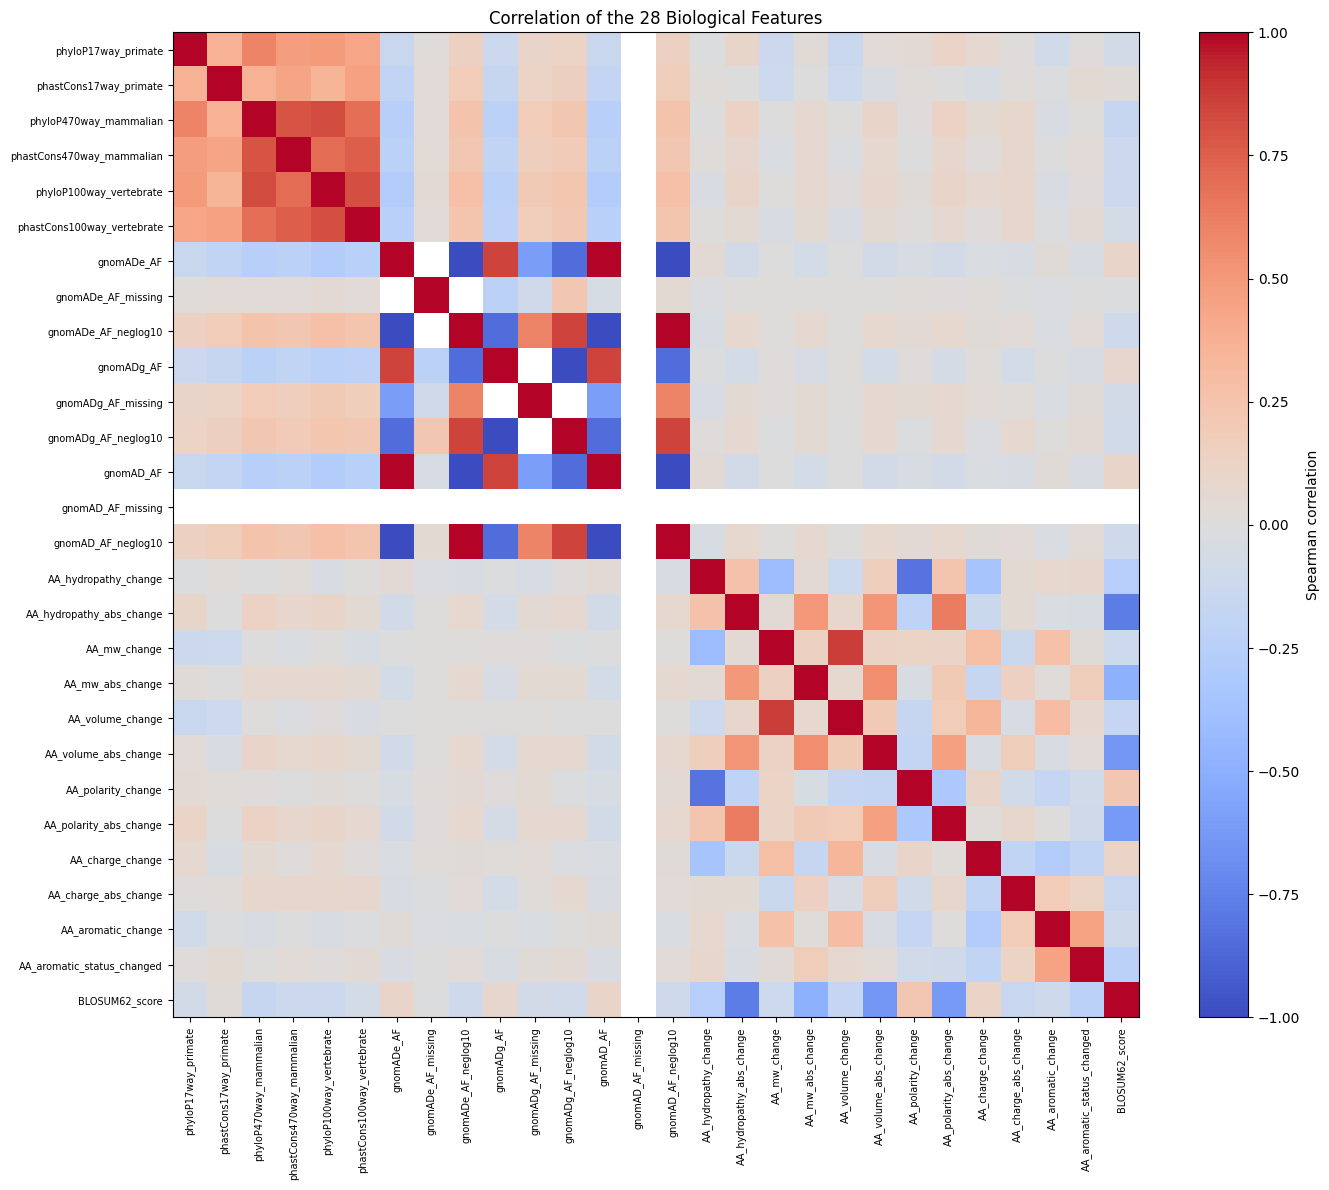

In [18]:
corr = expanded[primary_feature_cols].corr(method="spearman")

plt.figure(figsize=(14, 12))
im = plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
plt.colorbar(im, label="Spearman correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=7)
plt.yticks(range(len(corr.index)), corr.index, fontsize=7)
plt.title("Correlation of the 28 Biological Features")
plt.tight_layout()
plt.show()

## 18. Save the files

Save the outputs and print a checksum for each, so the team can confirm they have the same files.

In [19]:
identifier_cols = [
    "VariationID",
    "GeneSymbol",
    "Chromosome",
    "PositionVCF",
    "ReferenceAlleleVCF",
    "AlternateAlleleVCF",
    "Assembly",
]
raw_biology_cols = [c for c in ["Amino_acids", "Variant", "Protein_position"] if c in expanded.columns]
extra_cols = [c for c in ["AA_ref", "AA_alt", "Protein_position_numeric"] if c in expanded.columns]
target_cols = ["BinaryClinicalSignificance", "label"]

model_cols = ["VariationID", "GeneSymbol"] + primary_feature_cols + target_cols
full_cols = list(dict.fromkeys(
    identifier_cols + raw_biology_cols + primary_feature_cols + extra_cols + benchmark_cols + target_cols
))
archive_cols = list(dict.fromkeys(source_cols + ["AA_ref", "AA_alt"] + conservation_cols + ["exclusion_reason"]))

MODEL_OUTPUT = WORKDIR / "clinvar_expanded_model_features.csv"
FULL_OUTPUT = WORKDIR / "clinvar_expanded_project_dataset.csv"
ARCHIVE_OUTPUT = WORKDIR / "clinvar_full_annotated_all_rows.csv"
CONFIG_OUTPUT = WORKDIR / "feature_config.json"

expanded[model_cols].to_csv(MODEL_OUTPUT, index=False)
expanded[full_cols].to_csv(FULL_OUTPUT, index=False)
df[archive_cols].to_csv(ARCHIVE_OUTPUT, index=False)

feature_config = {
    "target": "label",
    "group_column": "GeneSymbol",
    "feature_groups": FEATURE_GROUPS,
    "feature_sets": FEATURE_SETS,
}
with open(CONFIG_OUTPUT, "w") as f:
    json.dump(feature_config, f, indent=2)

outputs = {
    MODEL_OUTPUT: expanded[model_cols].shape,
    FULL_OUTPUT: expanded[full_cols].shape,
    ARCHIVE_OUTPUT: df[archive_cols].shape,
    CONFIG_OUTPUT: None,
}

display(pd.DataFrame([
    {
        "file": path.name,
        "rows": shape[0] if shape else "",
        "columns": shape[1] if shape else "",
        "size_mb": round(path.stat().st_size / 1024**2, 2),
        "md5": md5sum(path),
    }
    for path, shape in outputs.items()
]))

,file,rows,columns,size_mb,md5
0,clinvar_expanded_model_features.csv,46012,32,11.43,41d7d42d2600f7398e682dc025c37c41
1,clinvar_expanded_project_dataset.csv,46012,55,18.00,c31df0b8025293ae103fbd7dc05708c3
2,clinvar_full_annotated_all_rows.csv,46050,79,71.31,4dd022ad2e66dd51e531f64457d6c9f6
3,feature_config.json,,,0.00,bd053b9b568ec2258bf06ec1e660e2bb


## 19. Summary

In [20]:
summary = pd.Series({
    "Rows in source file": len(df),
    "Rows removed by cohort checks": int((df["exclusion_reason"].notna() & df["exclusion_reason"].ne("missing_conservation")).sum()),
    "Rows removed for missing conservation": int(df["exclusion_reason"].eq("missing_conservation").sum()),
    "Rows in final dataset": len(expanded),
    "Unique genes": expanded["GeneSymbol"].nunique(),
    "Benign": int(expanded["label"].eq(0).sum()),
    "Pathogenic": int(expanded["label"].eq(1).sum()),
    "Conservation features": len(conservation_cols),
    "Population features": len(population_feature_cols),
    "Amino acid features": len(aa_feature_cols),
    "Total features": len(primary_feature_cols),
    "Benchmark predictors kept": len(benchmark_cols),
}, name="value")

display(summary.to_frame())

,value
Rows in source file,46050
Rows removed by cohort checks,0
Rows removed for missing conservation,38
Rows in final dataset,46012
Unique genes,2105
Benign,32013
Pathogenic,13999
Conservation features,6
Population features,9
Amino acid features,13


## 20. Download the files

Downloads the model file, project file and feature list in Colab. Remove the # on the last line to also download the archive file.

In [21]:
try:
    from google.colab import files
except ImportError:
    files = None

if files is None:
    print("Not running in Colab. The files are saved in", WORKDIR)
else:
    files.download(str(MODEL_OUTPUT))
    files.download(str(FULL_OUTPUT))
    files.download(str(CONFIG_OUTPUT))
    # files.download(str(ARCHIVE_OUTPUT))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 21. Using the files

How to load the data and select feature set A, B or D. Make any further changes in your own notebook and keep the shared files unchanged.

In [22]:
model_df = pd.read_csv(MODEL_OUTPUT)

with open(CONFIG_OUTPUT) as f:
    config = json.load(f)

X_A = model_df[config["feature_sets"]["A"]]
X_B = model_df[config["feature_sets"]["B"]]
X_D = model_df[config["feature_sets"]["D"]]
y = model_df[config["target"]]
genes = model_df[config["group_column"]]

print("Set A:", X_A.shape)
print("Set B:", X_B.shape)
print("Set D:", X_D.shape)
print("Pathogenic share:", f"{y.mean():.2%}")
print("Genes:", genes.nunique())

Set A: (46012, 6)
Set B: (46012, 15)
Set D: (46012, 28)
Pathogenic share: 30.42%
Genes: 2105
